In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
df = pd.read_excel("/content/ghgp_data_by_year_2023.xlsx", sheet_name="LDC - Direct Emissions")
df

,Summary data collected by the Greenhouse Gas Reporting Program,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25
0,This data was reported to EPA by facilities as...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,All emissions data is presented in units of me...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Facility Id,FRS Id,Facility Name,State where Emissions Occur,Reported City,Reported State,Reported Zip Code,Reported Address,Reported County,Reported Latitude,...,2020 Total reported direct emissions from Loca...,2019 Total reported direct emissions from Loca...,2018 Total reported direct emissions from Loca...,2017 Total reported direct emissions from Loca...,2016 Total reported direct emissions from Loca...,2015 Total reported direct emissions from Loca...,2014 Total reported direct emissions from Loca...,2013 Total reported direct emissions from Loca...,2012 Total reported direct emissions from Loca...,2011 Total reported direct emissions from Loca...
3,1008026,110071160130,Ameren Illinois,IL,Peoria,IL,61602,300 Liberty Street,PEORIA COUNTY,40.69045,...,74939.996,74762.846,99558.146,74961.1,73739.346,105051.594,75801.6,75662.2,75480.25,73414.44
4,1004034,110071160131,Ameren Missouri,MO,St. Louis,MO,63103,1901 Chouteau Avenue,ST. LOUIS CITY,38.620667,...,14759.55,14674.95,13714.75,13668.5,13556.8,13459.2,13412.6,13353.6,13736.25,13271.75
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
206,1003558,110071160538,Waterville Gas & Oil Company,OH,Waterville,OH,43566,700 Farnsworth Rd.,LUCAS COUNTY,41.49916,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
207,1011115,110010642073,"West Texas Gas Utility, LLC",TX,Midland,TX,79705,303 Veterans Airpark Ln. Ste 5000,MIDLAND COUNTY,31.99906,...,31068.65,31950.75,32660.8,33870.3,33632,35567.8,34701.35,35376.5,35376.5,35376.5
208,1002025,110071161924,Wisconsin Power & Light Gas Distribution,WI,Madison,WI,53718,4902 North Biltmore Lane,DANE COUNTY,43.15217,...,21372.8,21428.4,20268.65,19805,19571.7,19264.2,17636.5,18285.1,18021.1,17562.298
209,1002250,110071160885,Wisconsin Public Service Corporation,WI,Green Bay,WI,54307,700 North Adams,BROWN COUNTY,44.518347,...,39796.998,40010.548,38662.8,37547.798,36968.098,35729.348,35367.198,35362.198,35333.698,34779.498


Part 1 : Dataset Structrue + Trends

In [14]:
df = pd.read_excel("/content/ghgp_data_by_year_2023.xlsx", sheet_name="LDC - Direct Emissions", skiprows=3)
df.head()

,Facility Id,FRS Id,Facility Name,State where Emissions Occur,Reported City,Reported State,Reported Zip Code,Reported Address,Reported County,Reported Latitude,...,2020 Total reported direct emissions from Local Distribution Companies,2019 Total reported direct emissions from Local Distribution Companies,2018 Total reported direct emissions from Local Distribution Companies,2017 Total reported direct emissions from Local Distribution Companies,2016 Total reported direct emissions from Local Distribution Companies,2015 Total reported direct emissions from Local Distribution Companies,2014 Total reported direct emissions from Local Distribution Companies,2013 Total reported direct emissions from Local Distribution Companies,2012 Total reported direct emissions from Local Distribution Companies,2011 Total reported direct emissions from Local Distribution Companies
0,1008026,1.100712e+11,Ameren Illinois,IL,Peoria,IL,61602,300 Liberty Street,PEORIA COUNTY,40.690450,...,74939.996,74762.846,99558.146,74961.100,73739.346,105051.594,75801.60,75662.2,75480.25,73414.44
1,1004034,1.100712e+11,Ameren Missouri,MO,St. Louis,MO,63103,1901 Chouteau Avenue,ST. LOUIS CITY,38.620667,...,14759.550,14674.950,13714.750,13668.500,13556.800,13459.200,13412.60,13353.6,13736.25,13271.75
2,1004975,1.100712e+11,Arkansas Oklahoma Gas Corp (AR),AR,Fort Smith,AR,72903,5030 South S Street,SEBASTIAN COUNTY,35.363559,...,NaN,NaN,NaN,8961.200,9771.050,11131.700,10870.50,10821.8,11025.50,11509.60
3,1006481,NaN,Arkansas Oklahoma Gas Corp (OK),OK,Fort Smith,AR,72903,5030 South S Street,NaN,35.363530,...,NaN,NaN,NaN,2983.450,2977.350,3220.500,2447.55,3111.7,3129.45,3426.50
4,1007872,1.100712e+11,Atlanta Gas Light Company,GA,Atlanta,GA,30309,Ten Peachtree Place,FULTON COUNTY,33.797114,...,165161.150,154525.296,156542.840,154795.438,151902.050,160923.894,155671.85,155513.8,191483.40,217658.90


In [15]:
#Dataset info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 208 entries, 0 to 207
Data columns (total 26 columns):
 #   Column                                                                  Non-Null Count  Dtype  
---  ------                                                                  --------------  -----  
 0   Facility Id                                                             208 non-null    int64  
 1   FRS Id                                                                  193 non-null    float64
 2   Facility Name                                                           208 non-null    object 
 3   State where Emissions Occur                                             201 non-null    object 
 4   Reported City                                                           208 non-null    object 
 5   Reported State                                                          208 non-null    object 
 6   Reported Zip Code                                                       208 non-nu

In [16]:
#Statistical summary
df.describe()

,Facility Id,FRS Id,Reported Zip Code,Reported Latitude,Reported Longitude,Primary NAICS Code,2023 Total reported direct emissions from Local Distribution Companies,2022 Total reported direct emissions from Local Distribution Companies,2021 Total reported direct emissions from Local Distribution Companies,2020 Total reported direct emissions from Local Distribution Companies,2019 Total reported direct emissions from Local Distribution Companies,2018 Total reported direct emissions from Local Distribution Companies,2017 Total reported direct emissions from Local Distribution Companies,2016 Total reported direct emissions from Local Distribution Companies,2015 Total reported direct emissions from Local Distribution Companies,2014 Total reported direct emissions from Local Distribution Companies,2013 Total reported direct emissions from Local Distribution Companies,2012 Total reported direct emissions from Local Distribution Companies,2011 Total reported direct emissions from Local Distribution Companies
count,2.080000e+02,1.930000e+02,208.000000,208.000000,208.000000,208.000000,1.570000e+02,1.610000e+02,1.670000e+02,1.660000e+02,1.650000e+02,1.640000e+02,1.710000e+02,1.710000e+02,1.770000e+02,1.810000e+02,1.760000e+02,1.830000e+02,1.830000e+02
mean,1.005024e+06,1.100665e+11,47777.802885,38.524461,-89.849182,227121.331731,7.258495e+04,7.292821e+04,7.244788e+04,7.441292e+04,7.592974e+04,7.878849e+04,7.821742e+04,8.199183e+04,8.225036e+04,8.161244e+04,8.614471e+04,8.422047e+04,8.561719e+04
std,2.663140e+03,1.210254e+07,26862.431274,4.604929,13.028731,54862.838190,1.311826e+05,1.298880e+05,1.311463e+05,1.367190e+05,1.395165e+05,1.428410e+05,1.450002e+05,1.550096e+05,1.562151e+05,1.499857e+05,1.564369e+05,1.561862e+05,1.606826e+05
min,1.000011e+06,1.100008e+11,2090.000000,26.710000,-122.672440,221121.000000,3.600000e+02,3.600000e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.003016e+06,1.100712e+11,26109.500000,35.293171,-96.816130,221210.000000,7.908500e+03,8.154200e+03,6.984450e+03,7.227513e+03,7.164350e+03,7.414025e+03,6.280300e+03,6.851950e+03,6.761350e+03,6.323600e+03,6.849762e+03,6.222275e+03,6.228275e+03
50%,1.004856e+06,1.100712e+11,47276.500000,39.213429,-87.962713,221210.000000,3.354725e+04,3.389830e+04,3.229765e+04,3.240500e+04,3.195075e+04,3.159775e+04,3.265105e+04,3.331435e+04,3.274490e+04,3.380995e+04,3.494277e+04,3.571625e+04,3.477950e+04
75%,1.006615e+06,1.100712e+11,71279.500000,41.630795,-80.049390,221210.000000,7.872180e+04,8.103000e+04,7.815057e+04,8.275570e+04,8.489845e+04,9.037188e+04,8.096192e+04,8.368245e+04,8.576629e+04,8.872980e+04,9.847775e+04,9.818050e+04,9.620910e+04
max,1.014465e+06,1.100712e+11,99336.000000,47.660000,-68.805810,921120.000000,1.287219e+06,1.251821e+06,1.255797e+06,1.309065e+06,1.307009e+06,1.313835e+06,1.318935e+06,1.330007e+06,1.331063e+06,1.333550e+06,1.357409e+06,1.385094e+06,1.350350e+06


In [17]:
#Calculate means for numeric columns only, then fill missing values
df = df.fillna(df.mean(numeric_only=True))

In [18]:
#Dataset info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 208 entries, 0 to 207
Data columns (total 26 columns):
 #   Column                                                                  Non-Null Count  Dtype  
---  ------                                                                  --------------  -----  
 0   Facility Id                                                             208 non-null    int64  
 1   FRS Id                                                                  208 non-null    float64
 2   Facility Name                                                           208 non-null    object 
 3   State where Emissions Occur                                             201 non-null    object 
 4   Reported City                                                           208 non-null    object 
 5   Reported State                                                          208 non-null    object 
 6   Reported Zip Code                                                       208 non-nu

In [21]:
#Convert entrie dataframe to numpy array
ghg_array = df.to_numpy()

#emissions columns are at indices 13 through 25
emissions_only = ghg_array[:, 13:].astype(float)

# Sum down columns ignoring missing values
column_sums = np.sum(emissions_only, axis=0)

<function matplotlib.pyplot.show(close=None, block=None)>

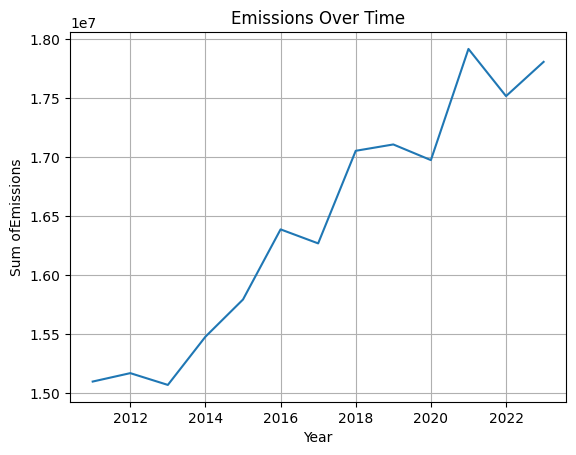

In [23]:
# Plot line chart
years = np.array([2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023])

plt.plot(years, column_sums)
plt.title("Emissions Over Time")
plt.xlabel("Year")
plt.ylabel("Sum ofEmissions")
plt.grid(True)
plt.show

In [ ]:
# 1. Define all emission columns
cols =